# Problem 2: MNIST Class Implementation and Testing

The `Mnist` class (`mnist.py`) is a 3-layer neural network that uses pretrained weights (`sample_weight.pkl`) and performs **forward propagation** only:

| layer | operation | output size |
|---|---|---|
| input | 28×28 image flattened, scaled to [0, 1] | 784 |
| hidden 1 | `sigmoid(x·W1 + b1)` | 50 |
| hidden 2 | `sigmoid(z1·W2 + b2)` | 100 |
| output | `softmax(z2·W3 + b3)` | 10 |

It is tested on 50 images of my own handwriting (five per digit), stored in `handwritten_digits/` as `n_m.png` (digit n, version m), 28×28×1 grayscale.

In [1]:
import os, glob
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

from mnist import Mnist

np.set_printoptions(precision=4, suppress=True)

## 1. Create the network and load the pretrained weights

In [2]:
mnist = Mnist('sample_weight.pkl')
for k in ['W1', 'b1', 'W2', 'b2', 'W3', 'b3']:
    print(f'{k}: {mnist.params[k].shape}')

W1: (784, 50)
b1: (50,)
W2: (50, 100)
b2: (100,)
W3: (100, 10)
b3: (10,)


## 2. My handwritten digit images
Each file must be 28×28 with one (grayscale) channel.

50 images
0_1.png size: (28, 28) mode: L (L = 1-channel grayscale)


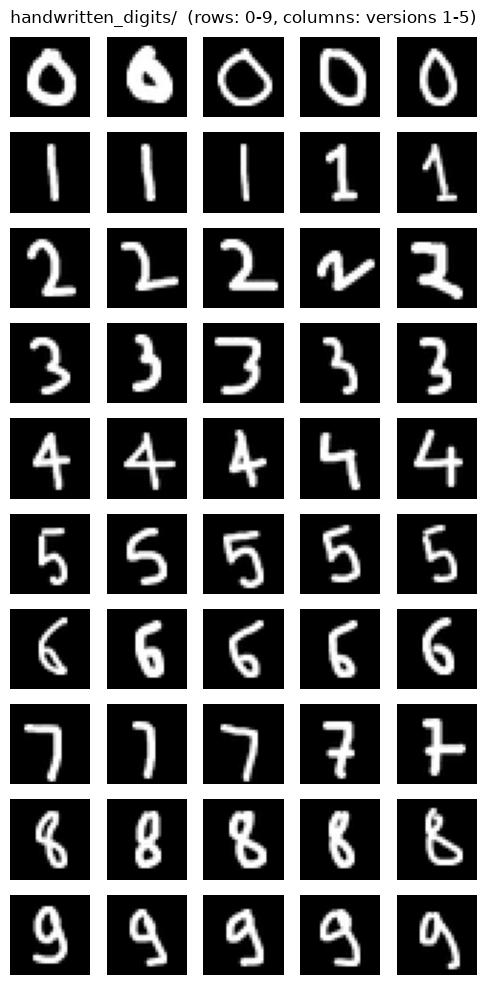

In [3]:
def sort_key(p):
    n, m = os.path.splitext(os.path.basename(p))[0].split('_')[:2]
    return int(n), int(m)

files = sorted(glob.glob('handwritten_digits/*_*.png'), key=sort_key)
print(len(files), 'images')
im = Image.open(files[0])
print(os.path.basename(files[0]), 'size:', im.size, 'mode:', im.mode, '(L = 1-channel grayscale)')
assert all(Image.open(f).size == (28, 28) for f in files)

fig, axes = plt.subplots(10, 5, figsize=(5, 10))
for ax in axes.ravel(): ax.axis('off')
for f in files:
    n, m = sort_key(f)
    if n < 10 and 1 <= m <= 5:
        axes[n, m - 1].imshow(Image.open(f), cmap='gray')
plt.suptitle('handwritten_digits/  (rows: 0-9, columns: versions 1-5)')
plt.tight_layout(); plt.show()

## 3. Forward propagation, step by step, for one image

In [4]:
img, x = mnist.load_image(files[0])
p = mnist.params
a1 = x @ p['W1'] + p['b1'];  z1 = mnist.sigmoid(a1)
a2 = z1 @ p['W2'] + p['b2']; z2 = mnist.sigmoid(a2)
a3 = z2 @ p['W3'] + p['b3']; y = mnist.softmax(a3)

print('x  :', x.shape)
print('z1 :', z1.shape, '(hidden layer 1, sigmoid)')
print('z2 :', z2.shape, '(hidden layer 2, sigmoid)')
print('y  :', y.shape, '(softmax output)')
print('\nclass probabilities:', y)
print('sum =', y.sum(), '  predicted digit =', y.argmax())
print('matches Mnist.forward():', np.allclose(y, mnist.forward(x)))

x  : (784,)
z1 : (50,) (hidden layer 1, sigmoid)
z2 : (100,) (hidden layer 2, sigmoid)
y  : (10,) (softmax output)

class probabilities: [0.994  0.     0.001  0.0001 0.     0.0043 0.0003 0.0001 0.0001 0.0001]
sum = 1.0   predicted digit = 0
matches Mnist.forward(): True


## 4. Test every image
For each image: show it with `imshow`, run inference, and print
- `Success: Image 2_1.png is for digit 2 is recognized as 2.` when the prediction is right
- `Fail: Image 2_1.png is for digit 2 but the inference result is 3.` when it is wrong

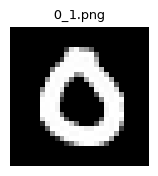

Success: Image 0_1.png is for digit 0 is recognized as 0.


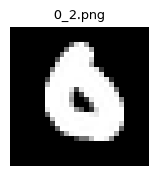

Fail: Image 0_2.png is for digit 0 but the inference result is 6.


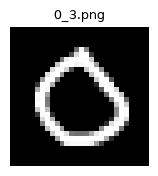

Success: Image 0_3.png is for digit 0 is recognized as 0.


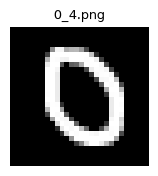

Success: Image 0_4.png is for digit 0 is recognized as 0.


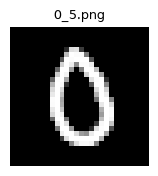

Success: Image 0_5.png is for digit 0 is recognized as 0.


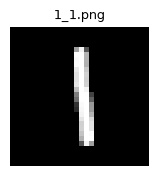

Success: Image 1_1.png is for digit 1 is recognized as 1.


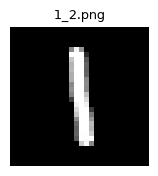

Success: Image 1_2.png is for digit 1 is recognized as 1.


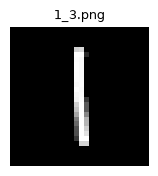

Success: Image 1_3.png is for digit 1 is recognized as 1.


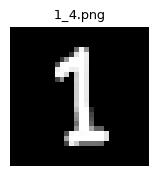

Success: Image 1_4.png is for digit 1 is recognized as 1.


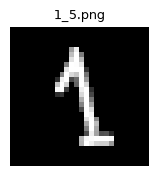

Success: Image 1_5.png is for digit 1 is recognized as 1.


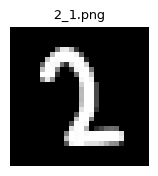

Success: Image 2_1.png is for digit 2 is recognized as 2.


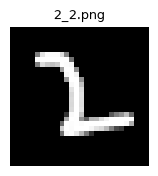

Success: Image 2_2.png is for digit 2 is recognized as 2.


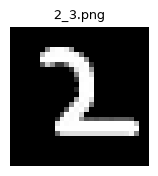

Success: Image 2_3.png is for digit 2 is recognized as 2.


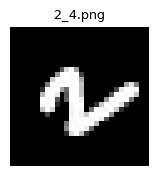

Fail: Image 2_4.png is for digit 2 but the inference result is 6.


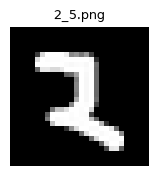

Success: Image 2_5.png is for digit 2 is recognized as 2.


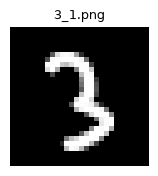

Success: Image 3_1.png is for digit 3 is recognized as 3.


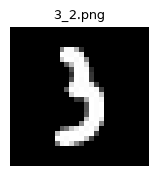

Success: Image 3_2.png is for digit 3 is recognized as 3.


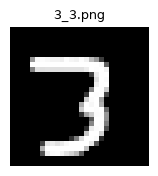

Success: Image 3_3.png is for digit 3 is recognized as 3.


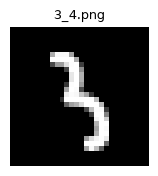

Success: Image 3_4.png is for digit 3 is recognized as 3.


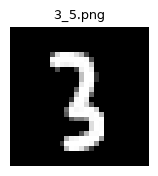

Success: Image 3_5.png is for digit 3 is recognized as 3.


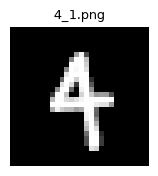

Fail: Image 4_1.png is for digit 4 but the inference result is 9.


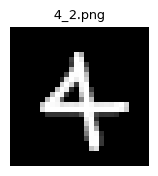

Success: Image 4_2.png is for digit 4 is recognized as 4.


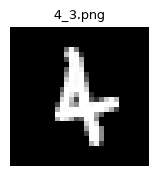

Success: Image 4_3.png is for digit 4 is recognized as 4.


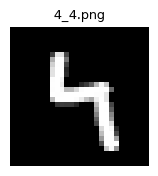

Success: Image 4_4.png is for digit 4 is recognized as 4.


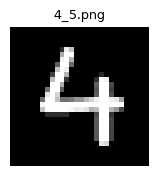

Success: Image 4_5.png is for digit 4 is recognized as 4.


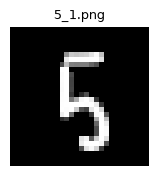

Fail: Image 5_1.png is for digit 5 but the inference result is 8.


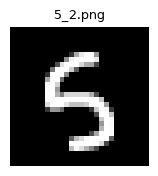

Success: Image 5_2.png is for digit 5 is recognized as 5.


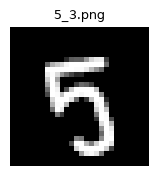

Fail: Image 5_3.png is for digit 5 but the inference result is 9.


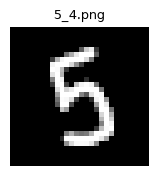

Success: Image 5_4.png is for digit 5 is recognized as 5.


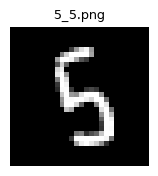

Success: Image 5_5.png is for digit 5 is recognized as 5.


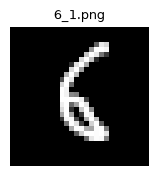

Success: Image 6_1.png is for digit 6 is recognized as 6.


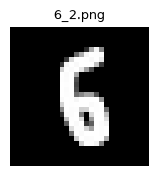

Success: Image 6_2.png is for digit 6 is recognized as 6.


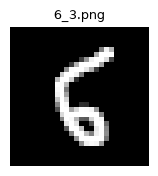

Success: Image 6_3.png is for digit 6 is recognized as 6.


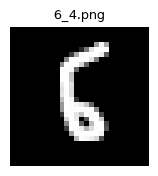

Success: Image 6_4.png is for digit 6 is recognized as 6.


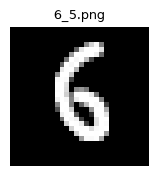

Success: Image 6_5.png is for digit 6 is recognized as 6.


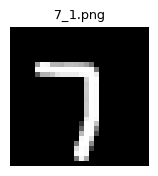

Success: Image 7_1.png is for digit 7 is recognized as 7.


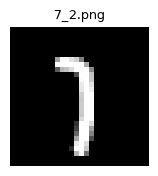

Success: Image 7_2.png is for digit 7 is recognized as 7.


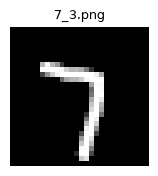

Success: Image 7_3.png is for digit 7 is recognized as 7.


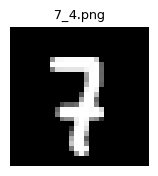

Success: Image 7_4.png is for digit 7 is recognized as 7.


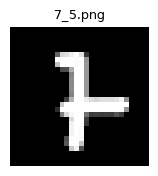

Fail: Image 7_5.png is for digit 7 but the inference result is 2.


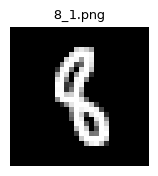

Success: Image 8_1.png is for digit 8 is recognized as 8.


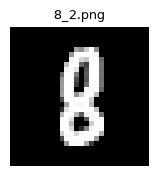

Success: Image 8_2.png is for digit 8 is recognized as 8.


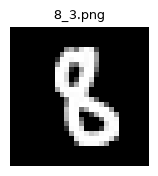

Success: Image 8_3.png is for digit 8 is recognized as 8.


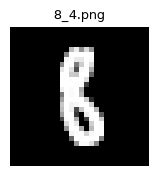

Success: Image 8_4.png is for digit 8 is recognized as 8.


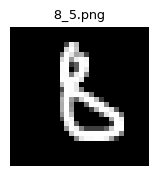

Fail: Image 8_5.png is for digit 8 but the inference result is 5.


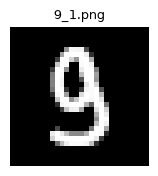

Fail: Image 9_1.png is for digit 9 but the inference result is 3.


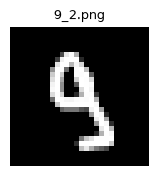

Fail: Image 9_2.png is for digit 9 but the inference result is 8.


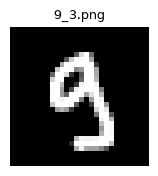

Success: Image 9_3.png is for digit 9 is recognized as 9.


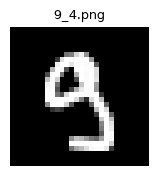

Success: Image 9_4.png is for digit 9 is recognized as 9.


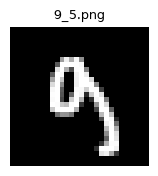

Success: Image 9_5.png is for digit 9 is recognized as 9.


In [5]:
results = []
for f in files:
    img, pred, true_digit, msg = mnist.test_image(f)
    results.append((os.path.basename(f), true_digit, pred))
    plt.figure(figsize=(1.8, 1.8))
    plt.imshow(img, cmap='gray')
    plt.title(os.path.basename(f), fontsize=9)
    plt.axis('off')
    plt.show()
    print(msg)

## 5. Summary

Overall accuracy: 41/50 = 82.0%

digit 0: 4/5 correct   (misread: 0_2.png->6)
digit 1: 5/5 correct
digit 2: 4/5 correct   (misread: 2_4.png->6)
digit 3: 5/5 correct
digit 4: 4/5 correct   (misread: 4_1.png->9)
digit 5: 3/5 correct   (misread: 5_1.png->8, 5_3.png->9)
digit 6: 5/5 correct
digit 7: 4/5 correct   (misread: 7_5.png->2)
digit 8: 4/5 correct   (misread: 8_5.png->5)
digit 9: 3/5 correct   (misread: 9_1.png->3, 9_2.png->8)


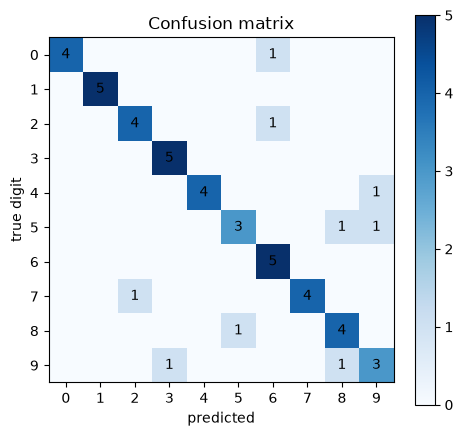

In [6]:
correct = sum(t == p for _, t, p in results)
print(f'Overall accuracy: {correct}/{len(results)} = {correct / len(results):.1%}\n')
for d in range(10):
    r = [(n, p) for n, t, p in results if t == d]
    ok = sum(p == d for _, p in r)
    wrong = ', '.join(f'{n}->{p}' for n, p in r if p != d)
    print(f'digit {d}: {ok}/{len(r)} correct' + (f'   (misread: {wrong})' if wrong else ''))

cm = np.zeros((10, 10), dtype=int)
for _, t, p in results: cm[t, p] += 1
plt.figure(figsize=(5, 4.5))
plt.imshow(cm, cmap='Blues')
for i in range(10):
    for j in range(10):
        if cm[i, j]: plt.text(j, i, cm[i, j], ha='center', va='center')
plt.xticks(range(10)); plt.yticks(range(10))
plt.xlabel('predicted'); plt.ylabel('true digit'); plt.title('Confusion matrix')
plt.colorbar(); plt.tight_layout(); plt.show()

**Note.** This small network was trained on MNIST, where digits are thick white strokes, centred by centre of mass inside a 20×20 box on a black 28×28 canvas. `Mnist.load_image` applies that same normalisation, but real handwriting still differs from MNIST style (stroke width, slant, how a 1, 4, 7 or 9 is written), so some misclassifications are expected; the network reaches about 93.5% on the official MNIST test set.